In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

print("Bibliothèques importées avec succès !")

Bibliothèques importées avec succès !


In [5]:
# Chemin du dataset
dataset_path = Path(r"C:\Users\kenza\Reconnaissance_Faciale\att_faces")

images = []
labels = []

# Parcourir uniquement les dossiers s1 à s40
person_folders = sorted(
    [p for p in dataset_path.iterdir()
     if p.is_dir() and p.name[1:].isdigit()],
    key=lambda x: int(x.name[1:])
)

for person_folder in person_folders:

    person_label = int(person_folder.name[1:])

    for image_path in sorted(person_folder.glob("*.pgm")):

        img = Image.open(image_path).convert("L")
        img_array = np.array(img)

        images.append(img_array)
        labels.append(person_label)

X = np.array(images)
y = np.array(labels)

print("Dataset chargé avec succès !")
print("Nombre d'images :", len(X))
print("Nombre de personnes :", len(np.unique(y)))
print("Dimensions des images :", X.shape)

Dataset chargé avec succès !
Nombre d'images : 400
Nombre de personnes : 40
Dimensions des images : (400, 112, 92)


In [6]:
print("Contenu du dossier :")

for element in dataset_path.iterdir():
    print(element.name, "| Dossier :", element.is_dir())

Contenu du dossier :
README | Dossier : False
s1 | Dossier : True
s10 | Dossier : True
s11 | Dossier : True
s12 | Dossier : True
s13 | Dossier : True
s14 | Dossier : True
s15 | Dossier : True
s16 | Dossier : True
s17 | Dossier : True
s18 | Dossier : True
s19 | Dossier : True
s2 | Dossier : True
s20 | Dossier : True
s21 | Dossier : True
s22 | Dossier : True
s23 | Dossier : True
s24 | Dossier : True
s25 | Dossier : True
s26 | Dossier : True
s27 | Dossier : True
s28 | Dossier : True
s29 | Dossier : True
s3 | Dossier : True
s30 | Dossier : True
s31 | Dossier : True
s32 | Dossier : True
s33 | Dossier : True
s34 | Dossier : True
s35 | Dossier : True
s36 | Dossier : True
s37 | Dossier : True
s38 | Dossier : True
s39 | Dossier : True
s4 | Dossier : True
s40 | Dossier : True
s5 | Dossier : True
s6 | Dossier : True
s7 | Dossier : True
s8 | Dossier : True
s9 | Dossier : True


In [7]:
person_folders = [
    p for p in dataset_path.iterdir()
    if p.is_dir() and p.name.startswith("s")
    and p.name[1:].isdigit()
]

print("Nombre de dossiers :", len(person_folders))
print("Noms :", [p.name for p in person_folders])

Nombre de dossiers : 40
Noms : ['s1', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's2', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's27', 's28', 's29', 's3', 's30', 's31', 's32', 's33', 's34', 's35', 's36', 's37', 's38', 's39', 's4', 's40', 's5', 's6', 's7', 's8', 's9']


In [8]:
# Afficher les fichiers du premier dossier
first_folder = dataset_path / "s1"

print("Contenu du dossier s1 :")

for file in first_folder.iterdir():
    print(file.name)

print("\nNombre d'images :", len(list(first_folder.glob("*.pgm"))))

Contenu du dossier s1 :
1.pgm
10.pgm
2.pgm
3.pgm
4.pgm
5.pgm
6.pgm
7.pgm
8.pgm
9.pgm

Nombre d'images : 10


In [9]:
images = []
labels = []

for person_folder in sorted(person_folders, key=lambda p: int(p.name[1:])):

    person_label = int(person_folder.name[1:])

    for image_path in person_folder.iterdir():

        if image_path.suffix.lower() == ".pgm":
            img = Image.open(image_path).convert("L")

            images.append(np.array(img))
            labels.append(person_label)

X = np.array(images)
y = np.array(labels)

print("Nombre total d'images :", len(X))
print("Nombre de personnes :", len(np.unique(y)))
print("Dimensions :", X.shape)

Nombre total d'images : 400
Nombre de personnes : 40
Dimensions : (400, 112, 92)


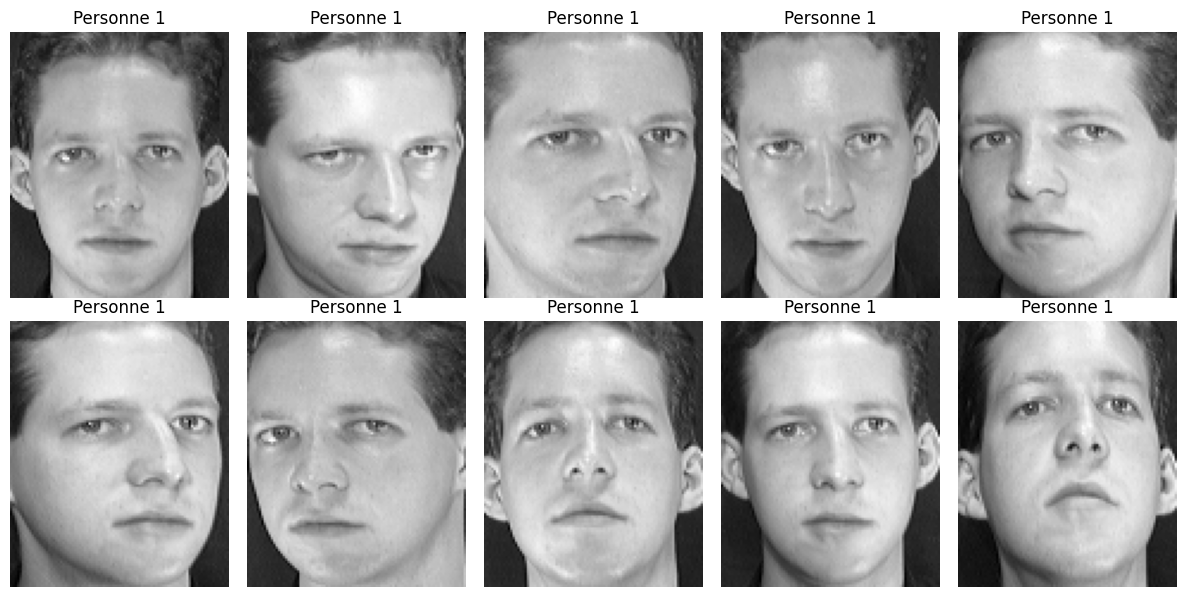

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title(f"Personne {y[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
print("Nombre d'images :", X.shape[0])
print("Hauteur :", X.shape[1])
print("Largeur :", X.shape[2])
print("Nombre de personnes :", len(np.unique(y)))
print("Images par personne :", np.unique(y, return_counts=True)[1])

Nombre d'images : 400
Hauteur : 112
Largeur : 92
Nombre de personnes : 40
Images par personne : [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]


In [12]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [13]:
# Transformer les images en vecteurs
X_flat = X.reshape(len(X), -1)

print("Dimensions avant transformation :", X.shape)
print("Dimensions après transformation :", X_flat.shape)

Dimensions avant transformation : (400, 112, 92)
Dimensions après transformation : (400, 10304)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_flat,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Images d'entraînement :", X_train.shape[0])
print("Images de test :", X_test.shape[0])
print("Personnes dans l'entraînement :", len(np.unique(y_train)))
print("Personnes dans le test :", len(np.unique(y_test)))

Images d'entraînement : 280
Images de test : 120
Personnes dans l'entraînement : 40
Personnes dans le test : 40


In [15]:
# Création du modèle PCA
pca = PCA(n_components=100, whiten=True, random_state=42)

# Entraînement de PCA
X_train_pca = pca.fit_transform(X_train)

# Transformation des données de test
X_test_pca = pca.transform(X_test)

print("Dimensions initiales :", X_train.shape)
print("Dimensions après PCA :", X_train_pca.shape)
print("Variance expliquée :", pca.explained_variance_ratio_.sum())

Dimensions initiales : (280, 10304)
Dimensions après PCA : (280, 100)
Variance expliquée : 0.9098216938953718


In [16]:
# Création du classificateur KNN
knn_pca = KNeighborsClassifier(n_neighbors=3)

# Entraînement
knn_pca.fit(X_train_pca, y_train)

# Prédiction
y_pred_pca = knn_pca.predict(X_test_pca)

# Évaluation
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("Résultats du modèle Eigenfaces (PCA)")
print("Accuracy :", round(accuracy_pca * 100, 2), "%")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_pca))

Résultats du modèle Eigenfaces (PCA)
Accuracy : 72.5 %

Rapport de classification :
              precision    recall  f1-score   support

           1       1.00      0.33      0.50         3
           2       1.00      0.67      0.80         3
           3       1.00      1.00      1.00         3
           4       0.75      1.00      0.86         3
           5       0.20      1.00      0.33         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         3
           9       0.60      1.00      0.75         3
          10       1.00      0.33      0.50         3
          11       1.00      0.67      0.80         3
          12       0.00      0.00      0.00         3
          13       1.00      1.00      1.00         3
          14       1.00      0.67      0.80         3
          15       0.75      1.00      0.86         3
          16       1.00      0.33      0.50        

C:\Users\kenza\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\kenza\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\kenza\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [17]:
# Création du modèle LDA
lda = LinearDiscriminantAnalysis(n_components=39)

# Entraînement de LDA
X_train_lda = lda.fit_transform(X_train, y_train)

# Transformation des données de test
X_test_lda = lda.transform(X_test)

print("Dimensions initiales :", X_train.shape)
print("Dimensions après LDA :", X_train_lda.shape)

Dimensions initiales : (280, 10304)
Dimensions après LDA : (280, 39)


In [18]:
# Création du classificateur KNN
knn_lda = KNeighborsClassifier(n_neighbors=3)

# Entraînement
knn_lda.fit(X_train_lda, y_train)

# Prédiction
y_pred_lda = knn_lda.predict(X_test_lda)

# Évaluation
accuracy_lda = accuracy_score(y_test, y_pred_lda)

print("Résultats du modèle Fisherfaces (LDA)")
print("Accuracy :", round(accuracy_lda * 100, 2), "%")

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_lda, zero_division=0))

Résultats du modèle Fisherfaces (LDA)
Accuracy : 95.83 %

Rapport de classification :
              precision    recall  f1-score   support

           1       1.00      0.67      0.80         3
           2       1.00      1.00      1.00         3
           3       0.75      1.00      0.86         3
           4       1.00      1.00      1.00         3
           5       0.75      1.00      0.86         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         3
          10       1.00      0.67      0.80         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         3
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         3
          16       1.00      1.00      1.00      

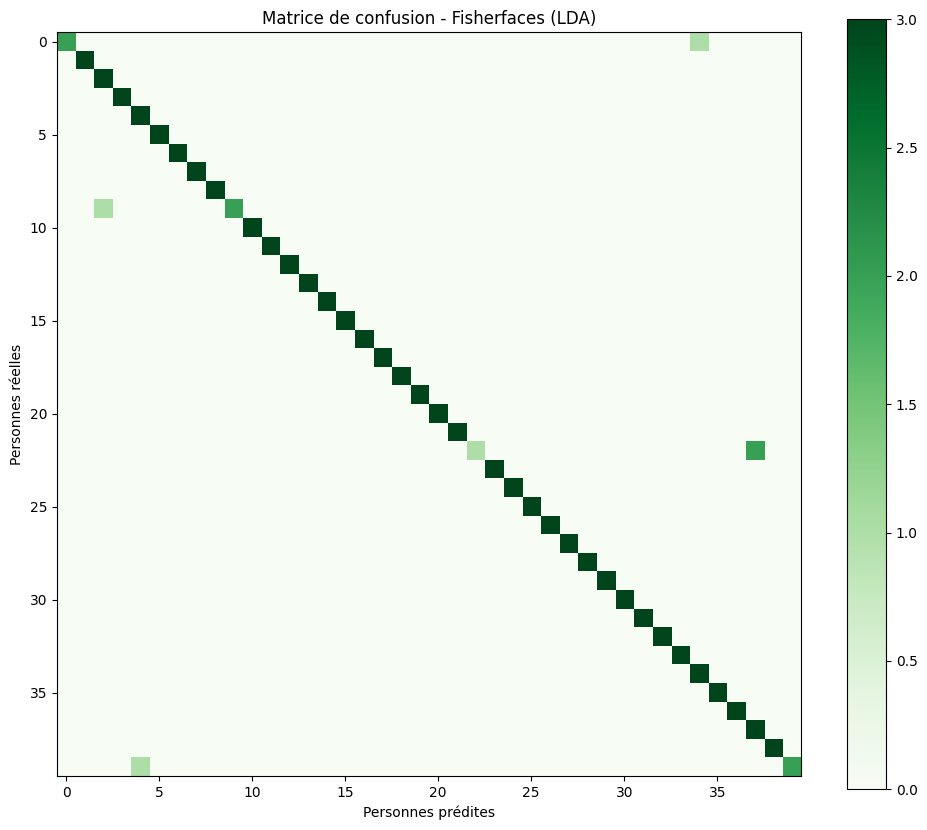

In [19]:
cm_lda = confusion_matrix(y_test, y_pred_lda)

plt.figure(figsize=(12, 10))
plt.imshow(cm_lda, cmap="Greens")
plt.title("Matrice de confusion - Fisherfaces (LDA)")
plt.xlabel("Personnes prédites")
plt.ylabel("Personnes réelles")
plt.colorbar()
plt.show()

In [20]:
print("COMPARAISON DES MODELES")
print("-------------------------")
print(f"Eigenfaces (PCA) : {accuracy_pca * 100:.2f}%")
print(f"Fisherfaces (LDA): {accuracy_lda * 100:.2f}%")

COMPARAISON DES MODELES
-------------------------
Eigenfaces (PCA) : 72.50%
Fisherfaces (LDA): 95.83%


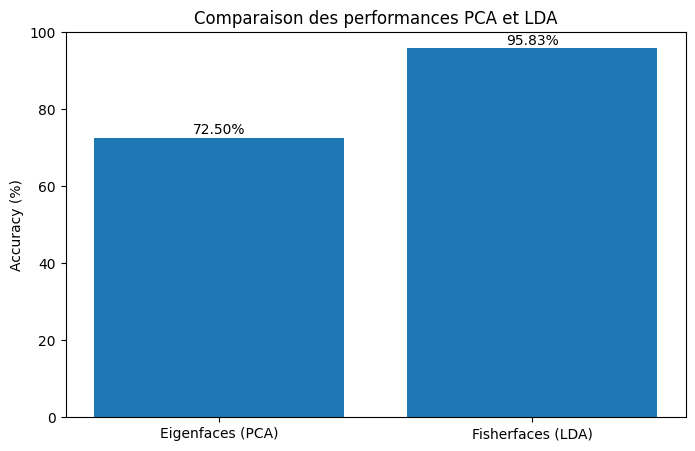

In [21]:
methodes = ["Eigenfaces (PCA)", "Fisherfaces (LDA)"]
accuracies = [accuracy_pca * 100, accuracy_lda * 100]

plt.figure(figsize=(8, 5))

bars = plt.bar(methodes, accuracies)

plt.title("Comparaison des performances PCA et LDA")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.show()

========== COMPARAISON DÉTAILLÉE ==========

Eigenfaces (PCA)
Accuracy  : 72.50%
Précision : 79.68%
Rappel    : 72.50%
F1-score  : 70.61%
Temps de prédiction : 0.151020 secondes

Fisherfaces (LDA)
Accuracy  : 95.83%
Précision : 97.12%
Rappel    : 95.83%
F1-score  : 95.55%
Temps de prédiction : 0.035281 secondes


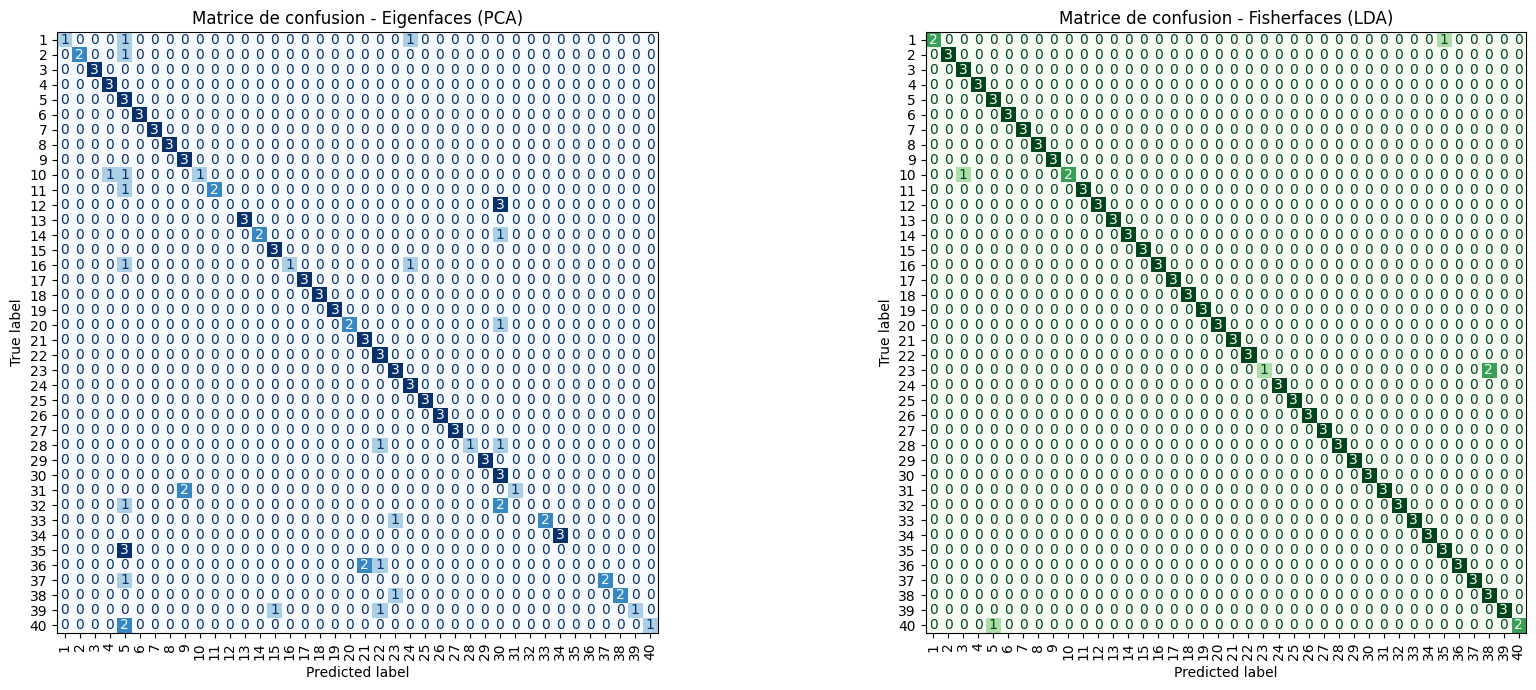

In [22]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# =====================================
# 1. Mesurer le temps de prédiction
# =====================================

# Eigenfaces (PCA)
start = time.perf_counter()

X_test_pca = pca.transform(X_test)
y_pred_pca = knn_pca.predict(X_test_pca)

temps_pca = time.perf_counter() - start

# Fisherfaces (LDA)
start = time.perf_counter()

X_test_lda = lda.transform(X_test)
y_pred_lda = knn_lda.predict(X_test_lda)

temps_lda = time.perf_counter() - start


# =====================================
# 2. Calculer les métriques
# =====================================

modeles = {
    "Eigenfaces (PCA)": y_pred_pca,
    "Fisherfaces (LDA)": y_pred_lda
}

print("========== COMPARAISON DÉTAILLÉE ==========")

for nom, predictions in modeles.items():

    accuracy = accuracy_score(y_test, predictions) * 100

    precision = precision_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    ) * 100

    rappel = recall_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    ) * 100

    f1 = f1_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    ) * 100

    temps = temps_pca if "PCA" in nom else temps_lda

    print(f"\n{nom}")
    print(f"Accuracy  : {accuracy:.2f}%")
    print(f"Précision : {precision:.2f}%")
    print(f"Rappel    : {rappel:.2f}%")
    print(f"F1-score  : {f1:.2f}%")
    print(f"Temps de prédiction : {temps:.6f} secondes")


# =====================================
# 3. Matrices de confusion
# =====================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

cm_pca = confusion_matrix(y_test, y_pred_pca, labels=np.arange(1, 41))
cm_lda = confusion_matrix(y_test, y_pred_lda, labels=np.arange(1, 41))

ConfusionMatrixDisplay(
    confusion_matrix=cm_pca,
    display_labels=np.arange(1, 41)
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Matrice de confusion - Eigenfaces (PCA)")
axes[0].tick_params(axis="x", labelrotation=90)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lda,
    display_labels=np.arange(1, 41)
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Matrice de confusion - Fisherfaces (LDA)")
axes[1].tick_params(axis="x", labelrotation=90)

plt.tight_layout()
plt.show()

In [23]:
import joblib

modeles = {
    "pca": pca,
    "knn_pca": knn_pca,
    "lda": lda,
    "knn_lda": knn_lda
}

joblib.dump(modeles, "modeles_orl.joblib")

print("Modèles enregistrés avec succès !")

Modèles enregistrés avec succès !


In [26]:
import joblib

chemin = r"C:\Users\kenza\Reconnaissance_Faciale\modeles_orl.joblib"

modeles = {
    "pca": pca,
    "knn_pca": knn_pca,
    "lda": lda,
    "knn_lda": knn_lda
}

joblib.dump(modeles, chemin)

print("Modèles enregistrés dans :", chemin)

Modèles enregistrés dans : C:\Users\kenza\Reconnaissance_Faciale\modeles_orl.joblib
